# 8. Internal flow and the Graetz problem

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 5 and 7

Inside a pipe the boundary layers of Chapter 7 grow from the wall until they meet at the
axis; after that the flow and, further on, the temperature profile stop changing shape.
Heat transfer inside pipes is then described by two numbers: the heat transfer
coefficient, and the *bulk* temperature of the fluid, which changes along the pipe as the
fluid gains or loses heat.

Two problems show the range. A viscous oil heated in a tube flows slowly, in laminar flow,
and its temperature profile never becomes fully developed in a tube of practical length:
how long must the heater be? And the hot water in the district-heating main of Chapter 1
flows fast and turbulently: how large is the heat transfer coefficient inside the pipe,
and how much does the water cool over a kilometre? The laminar problem was solved by
Graetz in 1883 as a series of eigenfunctions; a marching finite-volume solution checks it,
and also the case of a constant wall heat flux for Newtonian and shear-thinning fluids.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import convection_int, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_int, properties, reference
from engtransport.plotting import panel_label, use_style

use_style()
graetz = convection_int.graetz_series()

## 8.1 The bulk temperature

The temperature that matters for an energy balance is the *bulk* or mixing-cup temperature
$T_m$, the temperature the fluid would have if the flow through a cross-section were
collected and mixed. A steady energy balance on a length $dx$ of a pipe with perimeter $P$,
carrying a mass flow $\dot m$, gives

$$
\dot m\,c_p\,\frac{dT_m}{dx} = q''_s P ,
\tag{8.1}
$$

where $q''_s = h\,(T_w - T_m)$ is the heat flux from the wall. With the wall at a uniform
temperature $T_w$, Eq. (8.1) integrates to

$$
\frac{T_w - T_m(x)}{T_w - T_{m,\rm in}} = \exp\left(-\frac{\bar h P x}{\dot m c_p}\right) ,
\tag{8.2}
$$

with $\bar h$ the mean coefficient over the length $x$. The difference between wall and
fluid decays exponentially: a pipe cannot heat its fluid beyond the wall temperature, and
each additional metre does less. If instead the outside of the pipe loses heat to
surroundings at $T_\infty$ through a total resistance $R'$ per metre, the same result holds
with $\bar h P$ replaced by $1/R'$ and $T_w$ by $T_\infty$.

## 8.2 Laminar flow: fully developed and entry regions

In laminar flow at $\mathrm{Re}_D = \rho U D/\mu < 2300$ the velocity profile becomes the
parabola $u = 2U(1 - r^2/R^2)$ within about $0.05\,\mathrm{Re}_D D$ of the entrance. Far
downstream the temperature profile also takes a fixed shape, and the Nusselt number
$\mathrm{Nu}_D = hD/k$ becomes a constant:

$$
\mathrm{Nu}_D = 3.657 \quad (T_w \text{ uniform}), \qquad
\mathrm{Nu}_D = \frac{48}{11} = 4.364 \quad (q''_s \text{ uniform}) .
\tag{8.3}
$$

The second follows directly: with a uniform flux, $T_m$ rises linearly, the profile shifts
without changing shape, and integrating the energy equation twice across the parabola gives
48/11. The first needs the full problem.

Graetz solved it. Take the velocity as already parabolic, the inlet temperature uniform,
and the wall at $T_w$ from $x = 0$. With $\theta = (T - T_w)/(T_{\rm in} - T_w)$ and the axial
distance in the form $\zeta = (x/D)/(\mathrm{Re}_D\mathrm{Pr})$, separation of variables gives

$$
\theta = \sum_{n=1}^\infty C_n\,R_n\!\left(\frac{r}{R}\right) e^{-2\lambda_n^2\zeta}, \qquad
\frac{1}{\rho}\frac{d}{d\rho}\left(\rho\frac{dR_n}{d\rho}\right) + \lambda_n^2 (1 - \rho^2) R_n = 0 ,
\tag{8.4}
$$

with $R_n'(0) = 0$ and $R_n(1) = 0$. The eigenvalues are $\lambda_n = 2.7044$, 6.6790,
10.6734, …; far downstream only the first term remains and $\mathrm{Nu}_D \to \lambda_1^2/2
= 3.657$. Close to the entrance the thermal layer is thin and sees a velocity that grows
linearly from the wall, as in Section 7.1; Lévêque's solution for this region gives

$$
\mathrm{Nu}_x = 1.077\,\zeta^{-1/3}, \qquad \overline{\mathrm{Nu}} = 1.615\,\zeta^{-1/3}
\qquad (\zeta \ll 0.01) .
\tag{8.5}
$$

The local Nusselt number is within 5 % of 3.657 beyond $\zeta \approx 0.033$, so the thermal
entry length is

$$
L_{\rm th} \approx 0.033\,\mathrm{Re}_D\mathrm{Pr}\,D .
\tag{8.6}
$$

For oils, with $\mathrm{Pr}$ in the thousands, this is often longer than the whole pipe.
`convection_int.graetz_series` computes the eigenvalues by shooting, and returns
$\theta_m(\zeta)$ and the local and mean Nusselt numbers.

In [2]:
lam = graetz["lam"]
print(f"eigenvalues {lam[0]:.4f}, {lam[1]:.4f}, {lam[2]:.4f}; Nu far downstream lambda_1^2/2 = {lam[0]**2 / 2:.4f}")
zeta_5 = brentq(lambda z: graetz["Nu_x"](z) - 1.05 * lam[0] ** 2 / 2, 0.005, 0.2)
print(f"local Nu within 5 % of its final value beyond zeta = {zeta_5:.3f}")
for z in (0.001, 0.01, 0.1):
    print(f"zeta = {z:5.3f}: Nu_x = {graetz['Nu_x'](z):.3f}, mean Nu = {graetz['Nu_mean'](z):.3f}, theta_m = {graetz['theta_m'](z):.4f}")

eigenvalues 2.7044, 6.6790, 10.6734; Nu far downstream lambda_1^2/2 = 3.6568
local Nu within 5 % of its final value beyond zeta = 0.033
zeta = 0.001: Nu_x = 10.119, mean Nu = 15.386, theta_m = 0.9403
zeta = 0.010: Nu_x = 4.916, mean Nu = 7.155, theta_m = 0.7511
zeta = 0.100: Nu_x = 3.658, mean Nu = 4.156, theta_m = 0.1897


### A heater for viscous oil

An oil enters a tube 20 mm in diameter at 20 °C, with a mass flow of 0.02 kg/s, and must leave
at 80 °C. The tube wall is held at 100 °C by condensing steam outside it. Take for the oil
$\rho = 880$ kg/m³, $c_p = 1900$ J/(kg K), $k = 0.14$ W/(m K) and $\mu = 0.088$ Pa s, values at
about the mean temperature.

In [3]:
rho_o, cp_o, k_o, mu_o = 880.0, 1900.0, 0.14, 0.088
D, m_dot, T_in, T_out, T_wall = 0.020, 0.02, 20.0, 80.0, 100.0
Re = 4 * m_dot / (math.pi * D * mu_o)
Pr = mu_o * cp_o / k_o
theta_out = (T_wall - T_out) / (T_wall - T_in)
zeta_out = brentq(lambda z: graetz["theta_m"](z) - theta_out, 1e-4, 2.0)
L_graetz = zeta_out * D * Re * Pr
zeta_366 = -math.log(theta_out) / (4 * 3.657)               # Eq. (8.2) with Nu = 3.657 throughout
print(f"Re = {Re:.1f}, Pr = {Pr:.0f}, Re Pr = {Re * Pr:.0f}; thermal entry length {zeta_5 * Re * Pr * D:.0f} m")
print(f"tube length for 80 C: Graetz {L_graetz:.1f} m (mean Nu {graetz['Nu_mean'](zeta_out):.2f});"
      f" with Nu = 3.657 throughout {zeta_366 * D * Re * Pr:.1f} m")
print(f"hydrodynamic entry length 0.05 Re D = {0.05 * Re * D * 100:.1f} cm")

Re = 14.5, Pr = 1194, Re Pr = 17280; thermal entry length 12 m
tube length for 80 C: Graetz 28.0 m (mean Nu 4.27); with Nu = 3.657 throughout 32.8 m
hydrodynamic entry length 0.05 Re D = 1.4 cm


The oil needs a 28 m tube, folded into a coil or split into parallel tubes. The whole heater
lies in the thermal entry region, which would be 12 m long, so the mean Nusselt number,
4.27, is 17 % above the fully developed 3.657; designing with 3.657 would make the tube
17 % too long. The velocity profile, by contrast, develops within 1.4 cm, which justifies
the parabola: for $\mathrm{Pr} \gg 1$ momentum diffuses far faster than heat.

## 8.3 Turbulent flow: the district-heating main

Above $\mathrm{Re}_D \approx 10^4$ the flow is fully turbulent, and the profiles develop
within ten diameters. Gnielinski's correlation, built on the friction factor
$f = (0.790\ln\mathrm{Re}_D - 1.64)^{-2}$ for smooth pipes, fits measurements to about
±10 %:

$$
\mathrm{Nu}_D = \frac{(f/8)(\mathrm{Re}_D - 1000)\mathrm{Pr}}
{1 + 12.7\sqrt{f/8}\,(\mathrm{Pr}^{2/3} - 1)}
\qquad (3000 < \mathrm{Re}_D < 5 \times 10^6) .
\tag{8.7}
$$

The older Dittus–Boelter formula, $\mathrm{Nu}_D = 0.023\,\mathrm{Re}_D^{0.8}\mathrm{Pr}^{0.4}$,
is simpler and typically within 10–20 % of it. Water at 110 °C flows at 1 m/s through the
steel pipe of Chapter 1 (inner diameter 107 mm):

In [4]:
water = properties.water_properties(273.15 + 110.0)
D_i = 0.1143 - 2 * 0.0036
U_w = 1.0
Re_w = water["rho"] * U_w * D_i / water["mu"]
Nu_g = convection_int.nu_pipe_gnielinski(Re_w, water["Pr"])
h_i = Nu_g * water["k"] / D_i
print(f"Re = {Re_w:.0f}, Pr = {water['Pr']:.2f}: Gnielinski Nu = {Nu_g:.0f}, h = {h_i:.0f} W/(m2 K);"
      f" Dittus-Boelter Nu = {0.023 * Re_w**0.8 * water['Pr']**0.4:.0f}")
print(f"inner film resistance {1 / (h_i * math.pi * D_i):.5f} m K/W, against 2.223 m K/W for the insulation")
m_w = water["rho"] * U_w * math.pi * D_i**2 / 4
R_ins_tot = (110.0 + 35.0) / 63.7                           # Chapter 1: 63.7 W/m for a 145 K difference
R_bare = (110.0 + 35.0) / 1638.0                            # Chapter 1: bare pipe
for name, R in (("insulated", R_ins_tot), ("bare", R_bare)):
    drop = 145.0 * (1 - math.exp(-1000.0 / (m_w * water["cp"] * R)))
    print(f"{name:9s}: water cools by {drop:5.2f} K per km, Eq. (8.2)")

Re = 400006, Pr = 1.58: Gnielinski Nu = 909, h = 5773 W/(m2 K); Dittus-Boelter Nu = 838
inner film resistance 0.00051 m K/W, against 2.223 m K/W for the insulation
insulated: water cools by  1.75 K per km, Eq. (8.2)
bare     : water cools by 38.84 K per km, Eq. (8.2)


The inside coefficient is about 5800 W/(m² K), so the film inside the pipe adds a resistance
of 0.0005 m K/W, four thousand times less than the insulation: Chapter 1 was right to
ignore it. Through the insulated pipe, 8.6 kg/s of water loses 1.8 K per kilometre in
−35 °C air; through a bare pipe it would lose 39 K per kilometre.

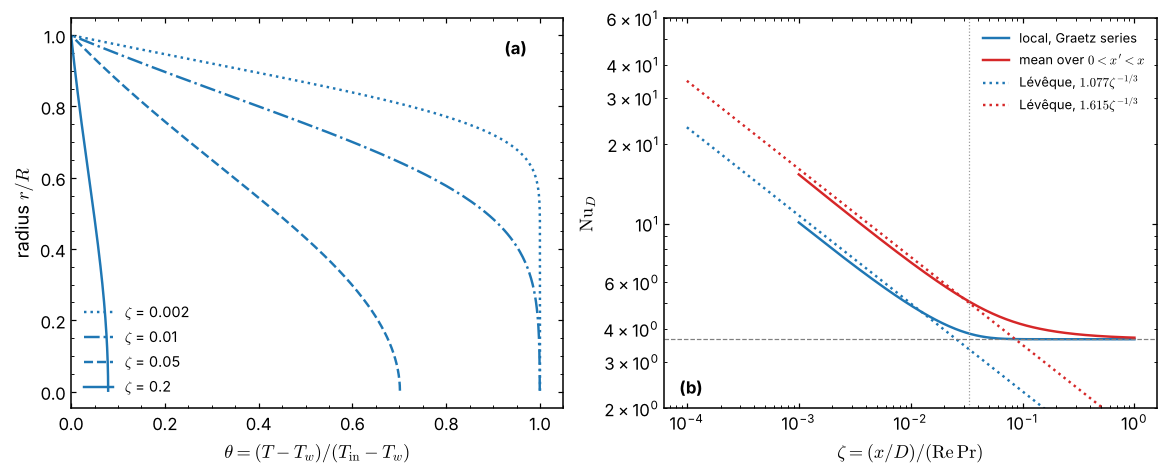

In [5]:
march = reference.graetz_march(1.0, n_r=200, n_x=600)
zs = np.geomspace(1e-3, 1.0, 200)                         # 12 terms of the series suffice here
zs_lev = np.geomspace(1e-4, 1.0, 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for z_snap, style in ((0.002, ":"), (0.01, "-."), (0.05, "--"), (0.2, "-")):
    m = reference.graetz_march(z_snap, n_r=200, n_x=200)
    ax1.plot(m["theta"], m["rho"], "C0" + style, label=rf"$\zeta$ = {z_snap:g}")
ax1.set_xlabel(r"$\theta = (T - T_w)/(T_{\rm in} - T_w)$")
ax1.set_ylabel(r"radius $r/R$")
ax1.set_xlim(0, 1.05)
ax1.legend(loc="lower left")
panel_label(ax1, "(a)", x=0.88)

ax2.loglog(zs, graetz["Nu_x"](zs), "C0", label="local, Graetz series")
ax2.loglog(zs, graetz["Nu_mean"](zs), "C3", label="mean over $0 < x' < x$")
ax2.loglog(zs_lev, 1.077 * zs_lev ** (-1 / 3), "C0:", label=r"Lévêque, $1.077\zeta^{-1/3}$")
ax2.loglog(zs_lev, 1.615 * zs_lev ** (-1 / 3), "C3:", label=r"Lévêque, $1.615\zeta^{-1/3}$")
ax2.axhline(3.657, color="0.5", lw=0.8, ls="--")
ax2.axvline(zeta_5, color="0.6", lw=0.8, ls=":")
ax2.set_xlabel(r"$\zeta = (x/D)/(\mathrm{Re}\,\mathrm{Pr})$")
ax2.set_ylabel(r"$\mathrm{Nu}_D$")
ax2.set_ylim(2, 60)
ax2.legend(loc="upper right", fontsize=8.5)
panel_label(ax2, "(b)", y=0.08)
plt.show()

**Figure 8.1.** (a) Temperature profiles across a tube with its wall held at a constant
temperature, at four distances from the start of heating (marching solution). (b) Local and
mean Nusselt numbers from the Graetz series, the Lévêque limit (8.5) near the entrance, and
the fully developed value 3.657; the dotted vertical line is the end of the thermal entry
region, Eq. (8.6).

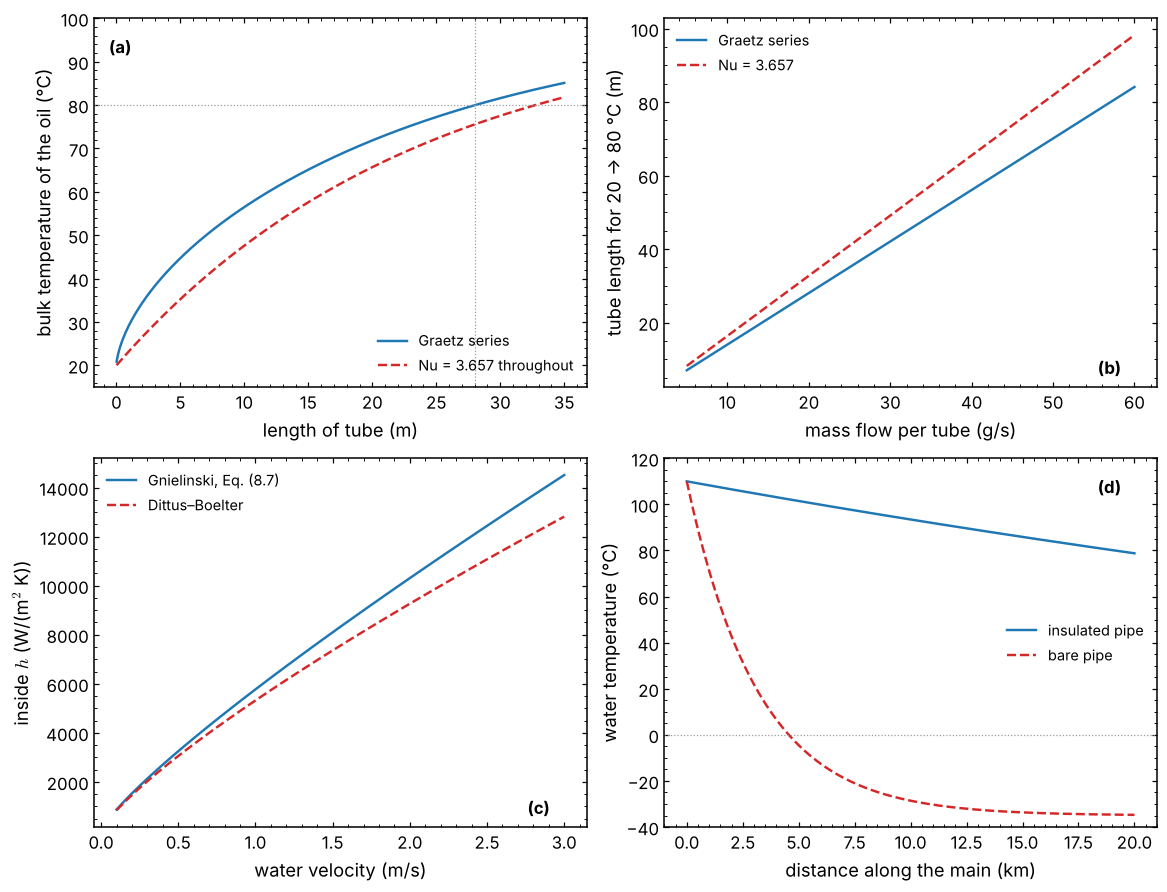

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
xs = np.linspace(0.01, 35, 300)
ax.plot(xs, T_wall - (T_wall - T_in) * graetz["theta_m"](xs / (D * Re * Pr)), "C0", label="Graetz series")
ax.plot(xs, T_wall - (T_wall - T_in) * np.exp(-4 * 3.657 * xs / (D * Re * Pr)), "C3--", label="Nu = 3.657 throughout")
ax.axhline(T_out, color="0.6", lw=0.8, ls=":")
ax.axvline(L_graetz, color="0.6", lw=0.8, ls=":")
ax.set_xlabel("length of tube (m)")
ax.set_ylabel("bulk temperature of the oil (°C)")
ax.set_ylim(15, 100)
ax.legend(loc="lower right")
panel_label(ax, "(a)")

ax = axes[0, 1]
flows = np.linspace(0.005, 0.06, 40)
L_req = [brentq(lambda z: graetz["theta_m"](z) - theta_out, 1e-5, 2.0) * D * 4 * mf / (math.pi * D * mu_o) * Pr
         for mf in flows]
ax.plot(flows * 1e3, L_req, "C0", label="Graetz series")
ax.plot(flows * 1e3, [zeta_366 * D * 4 * mf / (math.pi * D * mu_o) * Pr for mf in flows], "C3--", label="Nu = 3.657")
ax.set_xlabel("mass flow per tube (g/s)")
ax.set_ylabel("tube length for 20 → 80 °C (m)")
ax.legend(loc="upper left")
panel_label(ax, "(b)", x=0.88, y=0.08)

ax = axes[1, 0]
Us = np.linspace(0.1, 3.0, 60)
Res = water["rho"] * Us * D_i / water["mu"]
ax.plot(Us, [convection_int.nu_pipe_gnielinski(r, water["Pr"]) * water["k"] / D_i for r in Res], "C0",
        label="Gnielinski, Eq. (8.7)")
ax.plot(Us, 0.023 * Res**0.8 * water["Pr"] ** 0.4 * water["k"] / D_i, "C3--", label="Dittus–Boelter")
ax.set_xlabel("water velocity (m/s)")
ax.set_ylabel(r"inside $h$ (W/(m$^2$ K))")
ax.legend(loc="upper left")
panel_label(ax, "(c)", x=0.88, y=0.08)

ax = axes[1, 1]
km = np.linspace(0, 20, 200)
for name, R, style in (("insulated", R_ins_tot, "C0"), ("bare", R_bare, "C3--")):
    ax.plot(km, -35 + 145 * np.exp(-km * 1000 / (m_w * water["cp"] * R)), style, label=f"{name} pipe")
ax.axhline(0, color="0.6", lw=0.8, ls=":")
ax.set_xlabel("distance along the main (km)")
ax.set_ylabel("water temperature (°C)")
ax.set_ylim(-40, 120)
ax.legend(loc="center right")
panel_label(ax, "(d)", x=0.88)
plt.show()

**Figure 8.2.** (a) Bulk temperature of the oil along the heater tube, from the Graetz
series and with the fully developed Nusselt number throughout. (b) Tube length needed to
heat the oil from 20 to 80 °C against the mass flow per tube. (c) Heat transfer coefficient
inside the district-heating pipe of Chapter 1 against the water velocity. (d) Temperature
of water entering at 110 °C along an insulated and a bare main in −35 °C air, Eq. (8.2)
with the resistances of Chapter 1 (no allowance for freezing).

The length in Figure 8.2b grows in proportion to the flow, because $L = \zeta\,\mathrm{Re}\,
\mathrm{Pr}\,D$ at fixed outlet temperature. Halving the flow per tube halves the length;
that is why heaters use many tubes in parallel.

## 8.4 Checks

`reference.graetz_march` solves the energy equation itself, $u\,\partial\theta/\partial\zeta
= (4/\rho)\,\partial(\rho\,\partial\theta/\partial\rho)/\partial\rho$, by finite volumes in
$\rho$ and Crank–Nicolson steps in $\zeta$, starting from the uniform inlet temperature. It
accepts a uniform wall temperature or a uniform wall flux, and the velocity profile of a
power-law fluid, $u/U = \frac{3n+1}{n+1}(1 - \rho^{(n+1)/n})$, of which the parabola is
$n = 1$. Its constant-flux limit is tested against the exact fully developed result for a
power-law fluid,

$$
\mathrm{Nu}_D = \frac{8(5n+1)(3n+1)}{31n^2 + 12n + 1} ,
\tag{8.8}
$$

which gives 48/11 for $n = 1$ and 8 for plug flow ($n \to 0$).

In [7]:
cells = np.array([25, 50, 100, 200])
err_tm, err_nu = [], []
z_ref = np.array([0.003, 0.03, 0.3])
for nr in cells:
    m = reference.graetz_march(1.0, n_r=nr, n_x=4 * nr)
    tm = np.interp(np.log(z_ref), np.log(m["zeta"][1:]), m["theta_m"][1:])
    err_tm.append(np.max(np.abs(tm - graetz["theta_m"](z_ref))))
    nu = np.interp(np.log(z_ref), np.log(m["zeta"][1:]), m["Nu_x"][1:])
    err_nu.append(np.max(np.abs(nu / graetz["Nu_x"](z_ref) - 1)))
err_tm, err_nu = np.array(err_tm), np.array(err_nu)
order = -np.polyfit(np.log(cells), np.log(err_tm), 1)[0]
print(f"theta_m: largest error {err_tm[-1]:.1e} with 200 cells, order {order:.2f};"
      f" Nu_x within {err_nu[-1]:.1e}")

fine = reference.graetz_march(1.0, n_r=400, n_x=1200, zeta_start=1e-7)
for z in (1e-6, 1e-4, 1e-2):
    i = int(np.argmin(np.abs(fine["zeta"] - z)))
    print(f"zeta = {fine['zeta'][i]:.0e}: Nu_x zeta^1/3 = {fine['Nu_x'][i] * fine['zeta'][i] ** (1 / 3):.3f} (Leveque 1.077)")

flux = {}
for n_pl in (1.0, 0.5, 0.25):
    flux[n_pl] = reference.graetz_march(2.0, n_r=200, n_x=800, n=n_pl, wall="flux")
    exact = 8 * (5 * n_pl + 1) * (3 * n_pl + 1) / (31 * n_pl**2 + 12 * n_pl + 1)
    print(f"uniform flux, n = {n_pl:4.2f}: marching {flux[n_pl]['Nu_x'][-1]:.4f}, Eq. (8.8) {exact:.4f},"
          f" package {convection_int.nu_laminar_power_law_const_q(n_pl):.4f}")

theta_m: largest error 6.7e-06 with 200 cells, order 2.06; Nu_x within 4.8e-06
zeta = 1e-06: Nu_x zeta^1/3 = 1.065 (Leveque 1.077)
zeta = 1e-04: Nu_x zeta^1/3 = 1.034 (Leveque 1.077)
zeta = 1e-02: Nu_x zeta^1/3 = 1.059 (Leveque 1.077)
uniform flux, n = 1.00: marching 4.3637, Eq. (8.8) 4.3636, package 4.3636
uniform flux, n = 0.50: marching 4.7458, Eq. (8.8) 4.7458, package 4.7458
uniform flux, n = 0.25: marching 5.3054, Eq. (8.8) 5.3053, package 5.3053


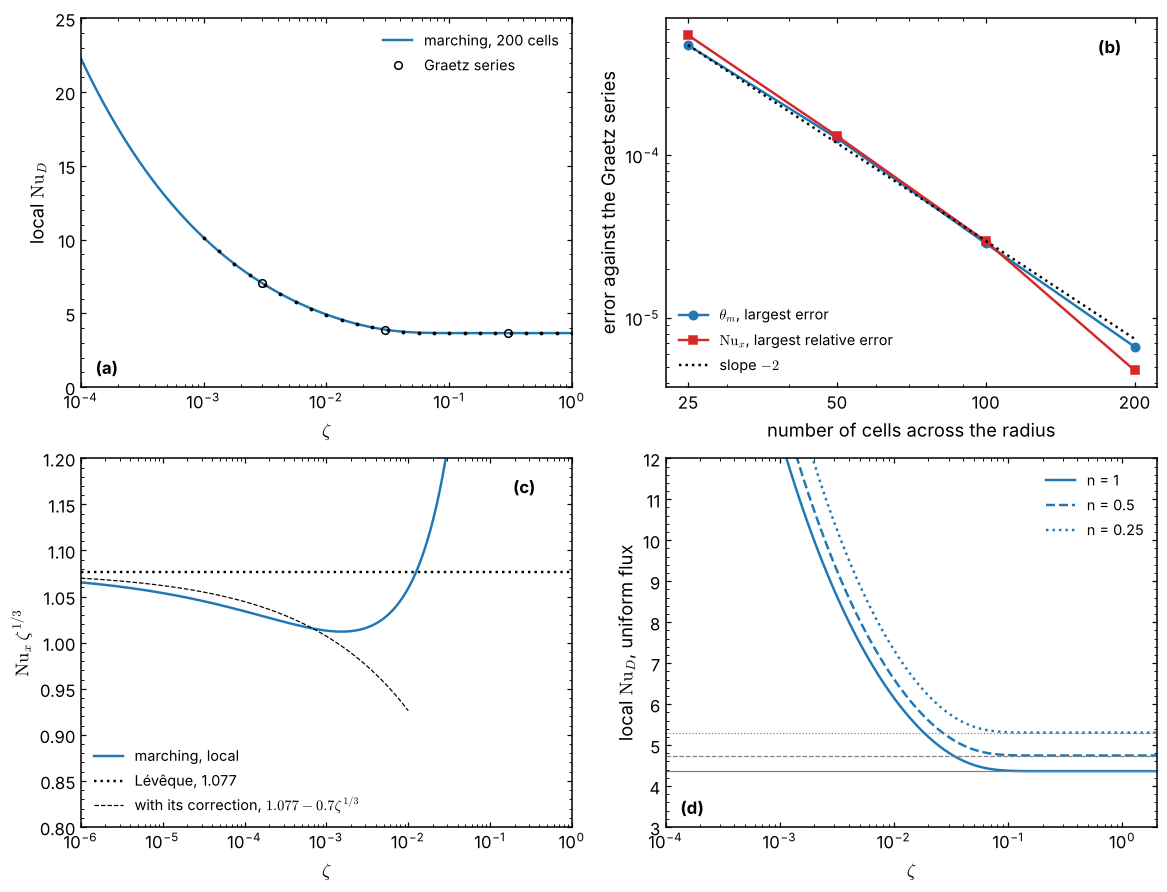

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
ax.semilogx(march["zeta"][1:], march["Nu_x"][1:], "C0", label="marching, 200 cells")
ax.semilogx(z_ref, graetz["Nu_x"](z_ref), "ko", ms=5, mfc="none", label="Graetz series")
zz = np.geomspace(1e-3, 1, 25)
ax.semilogx(zz, graetz["Nu_x"](zz), "k.", ms=3)
ax.set_xlim(1e-4, 1)
ax.set_ylim(0, 25)
ax.set_xlabel(r"$\zeta$")
ax.set_ylabel(r"local $\mathrm{Nu}_D$")
ax.legend(loc="upper right")
panel_label(ax, "(a)", y=0.08)

ax = axes[0, 1]
ax.loglog(cells, err_tm, "o-", label=r"$\theta_m$, largest error")
ax.loglog(cells, err_nu, "s-", color="C3", label=r"$\mathrm{Nu}_x$, largest relative error")
ax.loglog(cells, err_tm[0] * (cells[0] / cells) ** 2, "k:", label=r"slope $-2$")
ax.set_xticks([25, 50, 100, 200])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("number of cells across the radius")
ax.set_ylabel("error against the Graetz series")
ax.legend(loc="lower left")
panel_label(ax, "(b)", x=0.88)

ax = axes[1, 0]
sel = fine["zeta"] > 0
ax.semilogx(fine["zeta"][sel], fine["Nu_x"][sel] * fine["zeta"][sel] ** (1 / 3), "C0", label="marching, local")
ax.axhline(1.077, color="k", ls=":", label="Lévêque, 1.077")
zl = np.geomspace(1e-6, 1e-2, 100)
ax.semilogx(zl, 1.077 - 0.7 * zl ** (1 / 3), "k--", lw=0.8, label=r"with its correction, $1.077 - 0.7\zeta^{1/3}$")
ax.set_xlabel(r"$\zeta$")
ax.set_ylabel(r"$\mathrm{Nu}_x\,\zeta^{1/3}$")
ax.set_xlim(1e-6, 1)
ax.set_ylim(0.8, 1.2)
ax.legend(loc="lower left")
panel_label(ax, "(c)", x=0.88)

ax = axes[1, 1]
for (n_pl, m), style in zip(flux.items(), ("-", "--", ":")):
    exact = 8 * (5 * n_pl + 1) * (3 * n_pl + 1) / (31 * n_pl**2 + 12 * n_pl + 1)
    ax.semilogx(m["zeta"][1:], m["Nu_x"][1:], "C0" + style, label=f"n = {n_pl:g}")
    ax.axhline(exact, color="0.5", lw=0.8, ls=style)
ax.set_xlim(1e-4, 2)
ax.set_ylim(3, 12)
ax.set_xlabel(r"$\zeta$")
ax.set_ylabel(r"local $\mathrm{Nu}_D$, uniform flux")
ax.legend(loc="upper right")
panel_label(ax, "(d)", y=0.08)
plt.show()

**Figure 8.3.** Checks. (a) Local Nusselt number for a uniform wall temperature, from the
marching solution and the Graetz series (dots, shown where 12 terms suffice). (b) Errors of the marching solution against the
series as the radial grid is refined; the dotted line has slope −2. (c) The marching
solution near the entrance, scaled by $\zeta^{1/3}$, approaching Lévêque's 1.077 together with
its first correction. (d) Local
Nusselt number for a uniform wall flux, for a Newtonian fluid ($n = 1$) and two
shear-thinning fluids, approaching Eq. (8.8) (thin lines).

The marching solution, which knows nothing of eigenfunctions, converges on the Graetz
series at second order and agrees with it to $10^{-5}$ in $\theta_m$ with 200 cells. Near
the entrance it follows Lévêque's asymptote together with its first correction,
$\mathrm{Nu}_x = 1.077\,\zeta^{-1/3} - 0.7$, to within 1 % down to $\zeta = 10^{-6}$, where the
thermal layer spans only a few cells. With a uniform flux it settles on 48/11 for
the parabola and on Eq. (8.8) for shear-thinning fluids, whose blunter velocity profiles
carry more fluid past the wall and raise the heat transfer.

## 8.5 What to trust

* *Variable viscosity.* The oil of Section 8.2 is several times less viscous at the wall
  (100 °C) than at its inlet temperature, which distorts the velocity profile and raises the
  heat transfer; the usual correction multiplies Nu by $(\mu/\mu_w)^{0.14}$. Constant
  properties at the mean temperature are an approximation of 10–20 % for oils.
* *Natural convection* inside a slowly moving heated fluid adds secondary flows in
  horizontal tubes and can raise the heat transfer considerably at low Re; Chapter 9 treats buoyancy-driven flow.
* *Turbulent correlations* fit smooth pipes to about ±10 %; scale and corrosion in old
  steel mains roughen the wall and change the friction and the heat transfer.
* *The Graetz series* is exact for its assumptions; with 12 terms it is accurate beyond
  $\zeta \approx 10^{-3}$, and Lévêque's form takes over closer to the entrance.

## Summary

* The bulk temperature follows the energy balance (8.1); with a uniform wall temperature the
  difference $T_w - T_m$ decays exponentially along the pipe, Eq. (8.2).
* Fully developed laminar flow has $\mathrm{Nu}_D = 3.657$ for a uniform wall temperature
  and 4.364 for a uniform flux, Eq. (8.3).
* In the thermal entry region the Graetz series (8.4) applies; near the entrance
  $\mathrm{Nu}_x = 1.077\,\zeta^{-1/3}$, Eq. (8.5), and the entry length is
  $0.033\,\mathrm{Re}\,\mathrm{Pr}\,D$, Eq. (8.6).
* Turbulent flow in smooth pipes follows Gnielinski's correlation (8.7).
* Shear-thinning fluids transfer more heat in laminar flow, Eq. (8.8).

## Exercises

Sample solutions are in [`solutions/part2_convection/08_solutions.ipynb`](../../solutions/part2_convection/08_solutions.ipynb).

1. **Water instead of oil.** In the heater of Section 8.2, water ($\mathrm{Pr} = 3$, at a
   Reynolds number of 1000) replaces the oil. Compare the hydrodynamic and thermal entry
   lengths. Is the Graetz assumption of a developed velocity profile still reasonable, and
   which way does the error go?
2. **An electric heater.** Water at 15 °C flows at 0.01 kg/s through a tube 8 mm in diameter
   wrapped with a heating tape that delivers a uniform 10 kW/m² to the wall. Assuming laminar
   flow with a developed velocity profile ($k = 0.6$ W/(m K), $c_p = 4180$ J/(kg K),
   $\mu = 1.0 \times 10^{-3}$ Pa s), find the length needed to reach 45 °C and the wall
   temperature at the outlet. Use `reference.graetz_march` with `wall="flux"` to follow the
   wall temperature along the tube. Where is the wall hottest?
3. **Pumping against heat transfer.** For the district-heating main of Section 8.3, find
   the pumping power per kilometre ($\Delta p\,\dot V$ with $\Delta p = f\,(L/D)\,\rho U^2/2$)
   and the inside $h$ at 0.5, 1 and 2 m/s. By what factor does each change when the velocity
   doubles? Why does the operator not care about $h$ here?
4. **A shear-thinning food.** A fruit purée behaves as a power-law fluid with $n = 0.4$. It is
   heated in a tube with a uniform wall flux. Compare its fully developed Nusselt number with
   that of a Newtonian fluid, and use `reference.graetz_march` to find its thermal entry
   length (the $\zeta$ beyond which the local Nu is within 5 % of its final value).

## Suggested references

* L. Graetz, "Über die Wärmeleitungsfähigkeit von Flüssigkeiten", *Ann. Phys. Chem.* **18**,
  79 (1883).
* A. Lévêque, "Les lois de la transmission de chaleur par convection", *Annales des Mines*
  **13**, 201 (1928).
* V. Gnielinski, "New equations for heat and mass transfer in turbulent pipe and channel
  flow", *Int. Chem. Eng.* **16**, 359 (1976).
* R. K. Shah and A. L. London, *Laminar Flow Forced Convection in Ducts*, Advances in Heat
  Transfer, Supplement 1 (Academic Press, 1978).

---

**Previous:** [7. Boundary layers and external flow](07_boundary_layers.ipynb) &nbsp;·&nbsp; **Next:** [9. Natural convection](09_natural_convection.ipynb)